# Experiment 8: Text Summarization

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Analysing the meaning of sentences.
2. Implement text summarization on the IMDB Movie Reviews dataset.

**Dataset:** [IMDB Dataset of 50K Movie Reviews - Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews) (`IMDB Dataset.csv`, kept in this folder).

## Step 1: Install and import the required packages

In [ ]:
%pip install nltk spacy scikit-learn networkx pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import re
import pandas as pd
import nltk
import spacy
from nltk import word_tokenize, sent_tokenize

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "book_grammars"]:
    nltk.download(pkg, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

### Chart style

In [ ]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Analysing the meaning of sentences

The meaning of a sentence can be analysed at three levels:
1. **Word meaning:** many words have several senses; the context decides which one is meant.
2. **Who did what to whom:** the roles of the words (doer, action, receiver), which stay the same even when the sentence is rephrased.
3. **Logical meaning:** a precise representation in first-order logic that a computer can check against facts.

## 1.1 Word meaning: word sense disambiguation
WordNet lists every sense of a word. The **Lesk algorithm** picks the sense whose dictionary definition shares the most words with the sentence.

In [ ]:
from nltk.corpus import wordnet as wn
from nltk.wsd import lesk

print("Senses of 'bank' (noun) in WordNet:")
for s in wn.synsets("bank", pos="n")[:5]:
    print(f"  {s.name():<40} {s.definition()}")

Senses of 'bank' (noun) in WordNet:


  bank.n.01                                sloping land (especially the slope beside a body of water)
  depository_financial_institution.n.01    a financial institution that accepts deposits and channels the money into lending activities
  bank.n.03                                a long ridge or pile
  bank.n.04                                an arrangement of similar objects in a row or in tiers
  bank.n.05                                a supply or stock held in reserve for future use (especially in emergencies)


In [ ]:
examples = [
    ("I went to the bank to deposit my money", "bank", "n"),
    ("We sat on the bank of the river and watched the water", "bank", "n"),
    ("The power plant produces electricity for the whole city", "plant", "n"),
    ("She watered the plant on the window every morning", "plant", "n"),
]
pd.DataFrame([{"Sentence": s, "Word": w, "Sense chosen by Lesk": lesk(word_tokenize(s), w, p).name(),
               "Definition": lesk(word_tokenize(s), w, p).definition()} for s, w, p in examples])

,Sentence,Word,Sense chosen by Lesk,Definition
0,I went to the bank to deposit my money,bank,depository_financial_institution.n.01,a financial institution that accepts deposits ...
1,We sat on the bank of the river and watched th...,bank,bank.n.01,sloping land (especially the slope beside a bo...
2,The power plant produces electricity for the w...,plant,plant.n.02,(botany) a living organism lacking the power o...
3,She watered the plant on the window every morning,plant,plant.n.01,buildings for carrying on industrial labor


Lesk picks the right sense of *bank* in both sentences, but swaps the two senses of *plant*: it only counts overlapping words between the sentence and each dictionary definition, and here the wrong definitions happen to share more words. Modern systems use the meaning of the whole context (e.g. neural language models) instead.

## 1.2 Who did what to whom: semantic roles
Using spaCy's dependency parse, we extract the **agent** (who does the action), the **action** (verb), the **patient** (what or whom it is done to) and the **recipient**. An active sentence and its passive form have different word order but the same meaning, so they give the same roles.

In [ ]:
def phrase(tok):
    return " ".join(t.text for t in tok.subtree)

def semantic_roles(sentence):
    doc = nlp(sentence)
    rows = []
    for verb in [t for t in doc if t.pos_ == "VERB"]:
        role = {"Sentence": sentence, "Agent (who)": "", "Action": verb.lemma_, "Patient (what/whom)": "", "Recipient": ""}
        for child in verb.children:
            if child.dep_ == "nsubj":
                role["Agent (who)"] = phrase(child)
            elif child.dep_ == "nsubjpass":
                role["Patient (what/whom)"] = phrase(child)
            elif child.dep_ == "dobj":
                role["Patient (what/whom)"] = phrase(child)
            elif child.dep_ == "dative":
                role["Recipient"] = phrase(child) if child.pos_ != "ADP" else " ".join(phrase(c) for c in child.children)
            elif child.dep_ == "agent":                       # 'by the boy' in a passive sentence
                role["Agent (who)"] = " ".join(phrase(c) for c in child.children)
        rows.append(role)
    return rows

sents = [
    "The boy kicked the ball.",
    "The ball was kicked by the boy.",
    "Priya gave her brother a new laptop.",
    "A new laptop was given to her brother by Priya.",
    "The director praised the young actors.",
]
pd.DataFrame([r for s in sents for r in semantic_roles(s)])

,Sentence,Agent (who),Action,Patient (what/whom),Recipient
0,The boy kicked the ball.,The boy,kick,the ball,
1,The ball was kicked by the boy.,the boy,kick,The ball,
2,Priya gave her brother a new laptop.,Priya,give,a new laptop,her brother
3,A new laptop was given to her brother by Priya.,Priya,give,A new laptop,her brother
4,The director praised the young actors.,The director,praise,the young actors,


Sentences 1-2 and 3-4 are worded differently but produce the same roles, i.e. they have the same meaning.

## 1.3 Logical meaning: first-order logic
NLTK's semantic grammar (`simple-sem.fcfg`) builds a **logical form** for each sentence while parsing it, using lambda calculus:
- `walk(angus)` = Angus walks
- `exists x.(dog(x) & bark(x))` = there is some x that is a dog and barks
- `all x.(dog(x) -> chase(x, cyril))` = for every x, if x is a dog then x chases Cyril

In [ ]:
from nltk.sem import interpret_sents

GRAMMAR = "grammars/book_grammars/simple-sem.fcfg"
logic_sents = ["Angus walks", "Cyril sees Irene", "a dog barks", "every dog chases Cyril",
               "Irene sees a dog", "Angus gives a bone to every dog"]

for sent, results in zip(logic_sents, interpret_sents(logic_sents, GRAMMAR)):
    print(f"{sent:<34} ->  {results[0][1]}")

Angus walks                        ->  walk(angus)
Cyril sees Irene                   ->  see(cyril,irene)
a dog barks                        ->  exists x.(dog(x) & bark(x))
every dog chases Cyril             ->  all x.(dog(x) -> chase(x,cyril))
Irene sees a dog                   ->  exists z1.(dog(z1) & see(irene,z1))
Angus gives a bone to every dog    ->  all z3.(dog(z3) -> exists z2.(bone(z2) & give(angus,z2,z3)))


### Checking the meaning against a model of the world
A **model** lists the individuals that exist and the facts that are true about them. Each logical form can then be evaluated as **True** or **False** in that model.

In [ ]:
from nltk.sem import Valuation, Model, Assignment, evaluate_sents

world = Valuation.fromstring("""
angus => a
cyril => c
irene => i
boy => {a, c}
girl => {i}
dog => {d1, d2}
bone => {b1}
walk => {a, i}
bark => {d1}
see => {(a, i), (c, i), (i, d1)}
chase => {(d1, c), (d2, c)}
give => {(a, b1, d1)}
""")
model = Model(world.domain, world)
g = Assignment(world.domain)

print("Individuals:", sorted(world.domain))
print("Facts: Angus and Irene walk; dog d1 barks; both dogs chase Cyril; Angus gives the bone to dog d1 only.")
print()
test_sents = logic_sents + ["Cyril walks", "every dog barks"]
pd.DataFrame([{"Sentence": s, "Logical form": str(r[0][1]), "True in the model?": r[0][2]}
              for s, r in zip(test_sents, evaluate_sents(test_sents, GRAMMAR, model, g))])

Individuals: ['a', 'b1', 'c', 'd1', 'd2', 'i']
Facts: Angus and Irene walk; dog d1 barks; both dogs chase Cyril; Angus gives the bone to dog d1 only.



,Sentence,Logical form,True in the model?
0,Angus walks,walk(angus),True
1,Cyril sees Irene,"see(cyril,irene)",True
2,a dog barks,exists x.(dog(x) & bark(x)),True
3,every dog chases Cyril,"all x.(dog(x) -> chase(x,cyril))",True
4,Irene sees a dog,"exists z4.(dog(z4) & see(irene,z4))",True
5,Angus gives a bone to every dog,all z6.(dog(z6) -> exists z5.(bone(z5) & give(...,False
6,Cyril walks,walk(cyril),False
7,every dog barks,all x.(dog(x) -> bark(x)),False


# Part 2: Text summarization on IMDB reviews

**Extractive summarization** picks the most important sentences from a text and joins them in their original order. We implement two methods:
1. **Word-frequency method:** words that appear often in the review (ignoring stop words) are important, so a sentence's score is the sum of its words' frequencies.
2. **TextRank:** each sentence is a node in a graph, connected to other sentences by their TF-IDF cosine similarity. **PageRank** then scores the sentences, so the ones most similar to the rest of the review rank highest.

## 2.1 Load the dataset

In [ ]:
df = pd.read_csv("IMDB Dataset.csv")
df["review"] = df["review"].str.replace(r"<br\s*/?>", " ", regex=True).str.replace(r"\s+", " ", regex=True)
df["n_sentences"] = df["review"].apply(lambda r: len(sent_tokenize(r)))
print("Reviews:", len(df))
print("Average sentences per review:", round(df["n_sentences"].mean(), 1))

Reviews: 50000
Average sentences per review: 12.3


## 2.2 Word-frequency summarizer

In [ ]:
from nltk.corpus import stopwords
from collections import Counter

STOP = set(stopwords.words("english"))

def frequency_summary(text, ratio=0.3):
    sentences = sent_tokenize(text)
    words = [w.lower() for w in word_tokenize(text) if w.isalpha() and w.lower() not in STOP]
    freq = Counter(words)
    top = max(freq.values())
    weight = {w: c / top for w, c in freq.items()}              # normalise to 0-1
    scores = [sum(weight.get(w.lower(), 0) for w in word_tokenize(s)) for s in sentences]
    k = max(2, round(len(sentences) * ratio))
    keep = sorted(sorted(range(len(sentences)), key=lambda i: scores[i], reverse=True)[:k])
    return " ".join(sentences[i] for i in keep), sentences, scores, keep

## 2.3 TextRank summarizer

In [ ]:
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def textrank_summary(text, ratio=0.3):
    sentences = sent_tokenize(text)
    tfidf = TfidfVectorizer(stop_words="english").fit_transform(sentences)
    sim = cosine_similarity(tfidf)
    graph = nx.from_numpy_array(sim)
    rank = nx.pagerank(graph)
    scores = [rank[i] for i in range(len(sentences))]
    k = max(2, round(len(sentences) * ratio))
    keep = sorted(sorted(range(len(sentences)), key=lambda i: scores[i], reverse=True)[:k])
    return " ".join(sentences[i] for i in keep), sentences, scores, keep

## 2.4 Summarizing a review

In [ ]:
review = df[(df["n_sentences"].between(12, 16)) & (df["review"].str.len() < 1800)]["review"].iloc[0]

freq_sum, sentences, f_scores, f_keep = frequency_summary(review)
tr_sum, _, t_scores, t_keep = textrank_summary(review)

print(f"ORIGINAL REVIEW ({len(sentences)} sentences, {len(review.split())} words):")
print(review)
print()
print(f"FREQUENCY SUMMARY ({len(f_keep)} sentences, {len(freq_sum.split())} words):")
print(freq_sum)
print()
print(f"TEXTRANK SUMMARY ({len(t_keep)} sentences, {len(tr_sum.split())} words):")
print(tr_sum)

ORIGINAL REVIEW (13 sentences, 304 words):
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me. The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word. It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away. I would say the main appeal of the show is due 

### Sentence scores
Each bar is one sentence of the review; the darker bars are the sentences chosen for the summary. The frequency method adds up word weights, so long sentences tend to score higher; TextRank scores depend on how similar a sentence is to the rest of the review, so they are much more even.

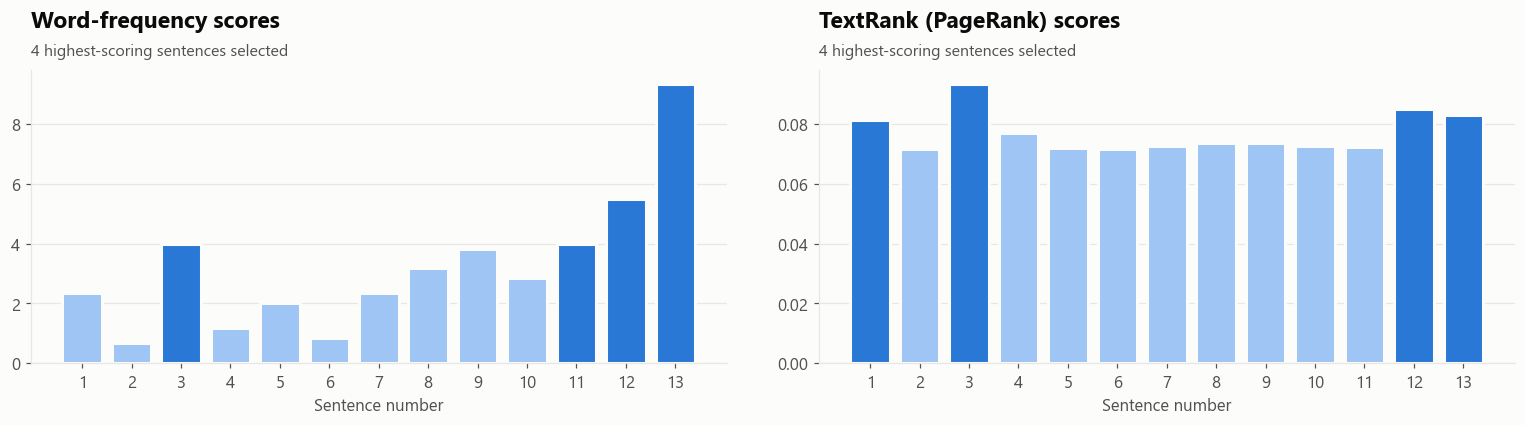

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, scores, keep, name in [(axes[0], f_scores, f_keep, "Word-frequency scores"),
                               (axes[1], t_scores, t_keep, "TextRank (PageRank) scores")]:
    colors = [BLUE if i in keep else BLUE_LIGHT for i in range(len(scores))]
    ax.bar(range(1, len(scores) + 1), scores, color=colors, edgecolor=SURFACE, linewidth=2)
    ax.set_xticks(range(1, len(scores) + 1))
    ax.set_xlabel("Sentence number")
    ax.grid(axis="y"); ax.set_axisbelow(True)
    titles(ax, name, f"{len(keep)} highest-scoring sentences selected")
plt.tight_layout(w_pad=3)
plt.show()

## 2.5 Summarizing several reviews

In [ ]:
sample = df[df["n_sentences"].between(10, 20)].sample(5, random_state=7)
rows = []
for _, r in sample.iterrows():
    summary = textrank_summary(r["review"])[0]
    rows.append({"Sentiment": r["sentiment"], "Original words": len(r["review"].split()),
                 "Summary words": len(summary.split()),
                 "Compression": f"{1 - len(summary.split()) / len(r['review'].split()):.0%}",
                 "TextRank summary": summary})
pd.set_option("display.max_colwidth", 400)
pd.DataFrame(rows)

,Sentiment,Original words,Summary words,Compression,TextRank summary
0,negative,152,65,57%,"This is by far the most vapid, idiotic, insanely stupid show that has EVER been on the air, and this is coming from someone who remembers ""San Pedro Beach Bums"". My wife loves watching reality shows--and there was one episode of this drivel where the wannabes had to develop a ""walk"". The end result was straight out of Monty Python's ""Ministry of Silly Walks"" sketch."
1,negative,244,79,68%,"Put shortly the movie is about a young couple inheriting a swanky house in LA, and are forced to get some roomies to make ends meet. These roommates eventually put both the young couple's patience and relationship to the test because they're so ""wild"". And here lies the problem of this movie: The protagonist couple are so anal-retentive and neurotic that they manage to generate zero sympathy. ..."
2,negative,318,66,79%,"In the XXII century an architect by the name of Merchant (Bruce Ramsay) commandeers a space station, which he personally designed. Upon arrival they find him partaking in a weird ritual with the use of a mysterious cubical. The movie that is essentially the same to Hellraiser, that The Quickening was to Highlander. Some decent gore in the flick, but apart from that an utter failure."
3,positive,293,103,65%,"Robert Montgomery & Walter Huston play submarine officers under the stress of war who quickly are at odds with each other, with dramatic and tragic results. The viewer is torn between the two strong characters, one of whom is governed by his heart and the other by the rules. Sterling Holloway creates a brief, vivid, portrait of a doomed seaman. Other moments of unexpected drama (Montgomery & M..."
4,negative,237,103,57%,"The real Partisan squadrons were established when RAF detached two of its (Yugoslav) squadrons of Spitfire Vc and, Hurricane IIc , respectively, manned by Ex Yugoslav Royal Airforce pilots, and allotted them to Tito's forces on the Island of Vis. So the film was one giant cow manure, to put it mildly, and the lowest point for its, otherwise not at all bad, director. By some quirk of fate I was..."


## Conclusion
**Part 1:** We analysed sentence meaning at three levels: the Lesk algorithm chose the correct WordNet sense of ambiguous words (*bank*, *plant*) from context; dependency parsing extracted who did what to whom, giving the same roles for active and passive versions of a sentence; and NLTK's semantic grammar translated sentences into first-order logic, which we evaluated as true or false in a model of the world.

**Part 2:** We implemented two extractive summarizers, a word-frequency method and TextRank, and applied them to IMDB reviews. Both keep about 30% of the sentences, reducing each review to its most informative sentences while keeping the original order.